### Country Algorithm Analysis
**Question:** which cryptographic algorithms do certificates mention, and does that differ by country?
- **CC:** the country is the certification scheme (`cert.scheme`).
- **FIPS 140:** records have no country field, so the country is the vendor's headquarters country.

**Sections:**
1. **Setup:** load the datasets and extract the algorithm mentions from each certificate.
2. **Algorithm usage by country:** heatmaps of how often each country's certificates mention each algorithm, and which algorithms are distinctive for a country.
3. **Confounders (CC only):** repeat the comparison within one product category and within one issue period, to separate the country effect from product mix and era.
4. **OpenSSL:** how OpenSSL adoption differs by country, which algorithms OpenSSL-based certificates mention, and whether OpenSSL explains the national ciphers.

Figures are saved to `img/` and tables to `results/`.

#### Setup
**What the cells do:**
1. The first cell imports the libraries and the extraction helpers `get_cc_algorithm_mentions` / `get_fips_algorithm_mentions` from `src/utils.py`.
2. The second cell loads both datasets from the local JSON files in `./datasets/` and sets `root_dir` so the certificate text files can be found. The datasets must be downloaded first (`python src/download_datasets.py`). The "older than your version" warnings are harmless.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sec_certs.dataset.cc import CCDataset
from sec_certs.dataset.fips import FIPSDataset

from src.utils import get_cc_algorithm_mentions, get_fips_algorithm_mentions

In [3]:
print("Loading datasets from JSON")
cc_dataset = CCDataset.from_json("./datasets/CC_dataset.json")
cc_dataset.root_dir = Path("./datasets")
print(f"Loaded {len(cc_dataset)} CC certificates from JSON")

fips_dataset = FIPSDataset.from_json("./datasets/FIPS_dataset.json")
fips_dataset.root_dir = Path("./datasets")
print(f"Loaded {len(fips_dataset)} FIPS 140 certificates from JSON")


Loading datasets from JSON
Loaded 6828 CC certificates from JSON
Loaded 5542 FIPS 140 certificates from JSON


Dataset was created with sec-certs version 0.4.1.post1.dev86+g770a181a4.d20260805 (older than your version 0.5.0.post1.dev4+g9ee2a63ba). To install the matching version: pip install sec-certs==0.4.1.post1.dev86+g770a181a4.d20260805
Dataset was created with sec-certs version 0.4.1.post1.dev138+ga5d8c122a.d20260911 (older than your version 0.5.0.post1.dev4+g9ee2a63ba). To install the matching version: pip install sec-certs==0.4.1.post1.dev138+ga5d8c122a.d20260911


#### Extracting algorithm mentions
**What the next cell does:** it turns each dataset into two DataFrames, then prints how many certificates and distinct algorithms remain.
- `cc_certs` / `fips_certs`: one row per certificate that has keyword data, with `Dgst`, `Country`, `Manufacturer`, `IssueDate`, `Year`, `Status`, and `Category` for CC. These are the denominators for every percentage below.
- `cc_mentions` / `fips_mentions`: one row per (certificate, algorithm) pair with the match count, plus the certificate's columns. For CC the count is split into `ReportCount` (certification report) and `TargetCount` (security target).

Algorithms come from the sec-certs keyword categories `symmetric_crypto`, `asymmetric_crypto`, `hash_function`, `pq_crypto` and `ecc_curve`.

**False-positive cleanup:** the sec-certs keyword regexes also match names that usually mean something else in certificate texts. Sampling the matched text gave two groups, both handled in `src/utils.py`:
- `FALSE_POSITIVE_ALGORITHMS` are dropped entirely. Examples: `HPC` (Health Professional Card), `E2` (interface names), `JH` (author initials), `Skinny` (Cisco SCCP), `MARS`, `Rainbow`, `Falcon`, `Saber`, `AEGIS` (products or vendors), `Lucifer` (historical note on DES), and `Elephant` (BitLocker's diffuser).
- `CONTEXT_CHECKED_ALGORITHMS` are recounted in the certificate text. A mention counts only if an occurrence falls outside a false context within 50 characters. `SEED` is excluded when it means the DRBG seed or DSA domain parameter, and bare `CAST` when it means a FIPS *Cryptographic Algorithm Self-Test*. `CAST5`, `CAST-128` and similar forms always count.

The context check reads the certificate text files, so this cell is slower than the others.

In [4]:
cc_certs, cc_mentions = get_cc_algorithm_mentions(cc_dataset)
fips_certs, fips_mentions = get_fips_algorithm_mentions(fips_dataset)
print(f"CC: {len(cc_certs)} certificates, {cc_mentions['Algorithm'].nunique()} algorithms")
print(f"FIPS: {len(fips_certs)} certificates, {fips_mentions['Algorithm'].nunique()} algorithms")

CC: 6819 certificates, 57 algorithms
FIPS: 5423 certificates, 59 algorithms


#### Certificates per country
**What the cell does:** it counts certificates per country in each dataset, to show how much data stands behind each country before comparing them. Countries with few certificates give noisy percentages, so later cells drop countries below a minimum count.

- **CC:** the country is the certification scheme.
- **FIPS 140:** there is no country field, so the vendor's headquarters country is looked up in `vendor_country` (`src/unification_dictionaries.py`) by unified vendor name. Vendors not in that dictionary become `Unknown`.

The cell also prints what share of FIPS certificates ended up as `Unknown`. These are left out of every country comparison, but they stay in the OpenSSL vs. other comparison further down, which doesn't use country.

In [5]:
coverage = pd.concat(
    {"CC": cc_certs["Country"].value_counts(), "FIPS": fips_certs["Country"].value_counts()}, axis=1
).fillna(0).astype(int).sort_values("CC", ascending=False)
print(f"FIPS certificates without a mapped vendor country: {(fips_certs['Country'] == 'Unknown').mean():.1%}")
coverage

FIPS certificates without a mapped vendor country: 25.0%


,CC,FIPS
Country,,
FR,1311,126
US,1275,3118
DE,1127,110
JP,728,140
CA,575,86
NL,464,60
ES,227,0
SE,184,7
KR,181,77


#### Algorithm usage by country
**Question:** how often do each country's certificates mention each algorithm?

**What the cells do:**
1. The first cell sets the thresholds and defines two helpers:
   - `country_algorithm_share` builds a country × algorithm table. Each cell is the % of the country's certificates that mention the algorithm at least once. Certificates are counted once however many times they mention it, and for CC the report and the security target count together. Countries with fewer than `MIN_CERTS` (50) certificates and `Unknown` are left out.
   - `plot_share_heatmap` draws such a table as a heatmap with algorithms as rows and countries as columns, keeping the `TOP_ALGORITHMS` (30) algorithms with the highest average share. The figure is drawn at its printed size for the thesis (at most `THESIS_TEXT_WIDTH` = 5 in wide, 6–7 pt fonts) and saved twice: as a PNG, and as a vector PDF with the same name for LaTeX. The title is printed above the figure rather than drawn in it, because the thesis caption carries it.

   It then computes `cc_share` and `fips_share` (it displays nothing).
2. The second cell draws the two heatmaps, `img/cc_country_algorithm_heatmap.png` and `img/fips_country_algorithm_heatmap.png`.

**Reading the labels:** some labels group several algorithms, because the sec-certs keyword dict stops at that level. `NIST`, `Brainpool`, `Curve` and `Edwards` are curve families, `RC` covers RC2/RC4/RC5, and `MAC` covers MAC constructions such as HMAC and CMAC.

In [19]:
MIN_CERTS = 50      # countries with fewer certificates are too noisy to compare
TOP_ALGORITHMS = 30


def country_algorithm_share(certs, mentions, min_certs=MIN_CERTS):
    """Percentage of each country's certificates that mention each algorithm."""
    totals = certs[certs["Country"] != "Unknown"]["Country"].value_counts()
    totals = totals[totals >= min_certs]
    counts = (mentions[mentions["Country"].isin(totals.index)]
              .groupby(["Country", "Algorithm"])["Dgst"].nunique()
              .unstack(fill_value=0))
    return counts.div(totals, axis=0).loc[totals.index] * 100


THESIS_TEXT_WIDTH = 5.0  # inches: \textwidth of the fithesis4 page (361 pt)


def plot_share_heatmap(share, title, path, top=TOP_ALGORITHMS):
    """Draw a share table as a heatmap at its printed thesis size.

    Algorithms are rows and countries are columns, so the figure fits the narrow
    thesis text column. Fonts are set for print (7 pt labels, 6 pt cell values), so
    include the figure in LaTeX at natural size, without a width= option. Saves a
    300 dpi PNG at `path` and a vector PDF with the same name for the thesis.
    """
    rows = share.mean().sort_values(ascending=False).head(top).index
    data = share[rows].T
    width = min(THESIS_TEXT_WIDTH, 1.6 + 0.3 * data.shape[1])
    height = 0.7 + 0.19 * data.shape[0]
    with plt.rc_context({"font.size": 7, "axes.labelsize": 7,
                         "xtick.labelsize": 7, "ytick.labelsize": 7}):
        fig, ax = plt.subplots(figsize=(width, height))
        sns.heatmap(data, annot=True, fmt=".0f", annot_kws={"fontsize": 6}, cmap="Blues",
                    vmin=0, vmax=100, linewidths=0.3, linecolor="white",
                    cbar_kws={"label": "% of certificates", "shrink": 0.5, "aspect": 30}, ax=ax)
        ax.set_xlabel("Country")
        ax.set_ylabel("Algorithm")
        ax.xaxis.tick_top()
        ax.xaxis.set_label_position("top")
        ax.tick_params(length=0)
        plt.setp(ax.get_xticklabels(), rotation=0)
        plt.setp(ax.get_yticklabels(), rotation=0)
        fig.tight_layout(pad=0.2)
        fig.savefig(path, dpi=300)
        fig.savefig(Path(path).with_suffix(".pdf"))
    print(title)  # the thesis caption carries the title, so it is not drawn in the figure
    plt.show()


cc_share = country_algorithm_share(cc_certs, cc_mentions)
fips_share = country_algorithm_share(fips_certs, fips_mentions)

CC: share of certificates mentioning each algorithm, by scheme
FIPS 140: share of certificates mentioning each algorithm, by vendor country


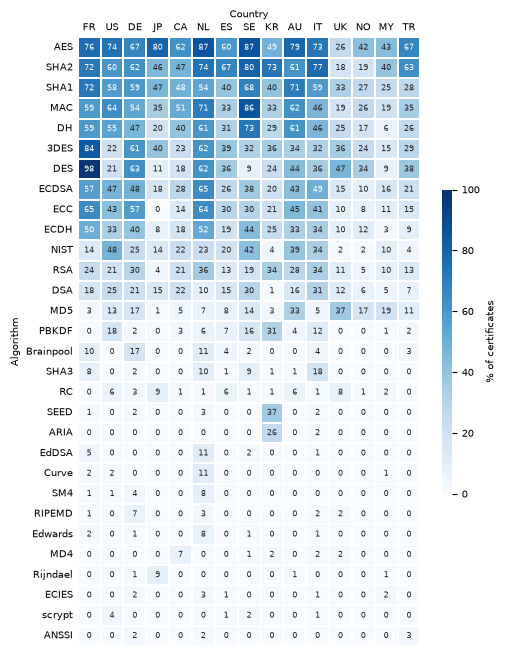

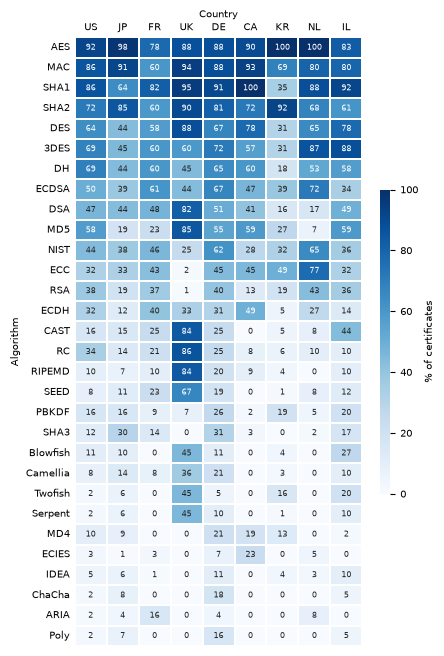

In [20]:
plot_share_heatmap(cc_share, "CC: share of certificates mentioning each algorithm, by scheme",
                   "./img/cc_country_algorithm_heatmap.png")
plot_share_heatmap(fips_share, "FIPS 140: share of certificates mentioning each algorithm, by vendor country",
                   "./img/fips_country_algorithm_heatmap.png")

#### Country-specific algorithms
**Question:** which algorithms does a country use much more than everyone else?

**Lift** is a country's share divided by the overall share across all certificates with a known country. For example, a lift of 20 means the country's certificates mention the algorithm 20× more often than certificates overall. To avoid ratios built on a handful of certificates, an algorithm is only considered for a country if at least `min_share` % (5 %) of the country's certificates mention it.

**What the cells do:**
1. The first cell defines `distinctive_algorithms`, which takes the top 5 algorithms by lift for each country. It saves the full lists to `results/cc_country_distinctive_algorithms.csv` and `results/fips_country_distinctive_algorithms.csv`, and shows the CC rows with lift ≥ 2.
2. The second cell shows the FIPS rows with lift ≥ 2.

Columns: `CountryShare` and `OverallShare` are % of certificates, and `Lift` is their ratio.

**Caveat for FIPS:** many countries come from only a few vendors (UK is almost entirely nCipher), so a high lift can reflect a single vendor's product line rather than a national preference. The FIPS overall share also leaves out the 25 % of certificates with unknown country, most of which come from smaller vendors.

In [8]:
def distinctive_algorithms(share, certs, mentions, min_share=5, top=5):
    """Algorithms each country uses far more than the dataset as a whole (lift = country % / overall %)."""
    known = certs[certs["Country"] != "Unknown"]
    overall = mentions[mentions["Country"] != "Unknown"].groupby("Algorithm")["Dgst"].nunique() / len(known) * 100
    lift = share.div(overall, axis=1)
    rows = []
    for country in share.index:
        candidates = lift.loc[country][share.loc[country] >= min_share].sort_values(ascending=False).head(top)
        for algorithm, value in candidates.items():
            rows.append({"Country": country, "Algorithm": algorithm,
                         "CountryShare": round(share.loc[country, algorithm], 1),
                         "OverallShare": round(overall[algorithm], 1), "Lift": round(value, 1)})
    return pd.DataFrame(rows)


cc_distinctive = distinctive_algorithms(cc_share, cc_certs, cc_mentions)
fips_distinctive = distinctive_algorithms(fips_share, fips_certs, fips_mentions)
cc_distinctive.to_csv("./results/cc_country_distinctive_algorithms.csv", index=False)
fips_distinctive.to_csv("./results/fips_country_distinctive_algorithms.csv", index=False)

cc_distinctive[cc_distinctive["Lift"] >= 2]

,Country,Algorithm,CountryShare,OverallShare,Lift
0,FR,SHA3,7.7,3.2,2.4
1,FR,DES,97.6,45.9,2.1
5,US,PBKDF,17.6,6.2,2.8
10,DE,RIPEMD,6.8,1.7,4.1
11,DE,Brainpool,16.9,5.8,2.9
15,JP,Rijndael,9.3,1.3,7.4
16,JP,RC,9.1,3.4,2.7
20,CA,MD4,7.1,0.8,9.0
25,NL,Curve,11.2,1.5,7.6
26,NL,Edwards,8.2,1.2,6.6


In [9]:
fips_distinctive[fips_distinctive["Lift"] >= 2]

,Country,Algorithm,CountryShare,OverallShare,Lift
5,JP,ChaCha,7.9,2.6,3.0
6,JP,Poly,7.1,2.5,2.9
7,JP,SHAKE,8.6,3.1,2.8
8,JP,SHA3,30.0,12.3,2.4
10,FR,ARIA,15.9,2.1,7.4
11,FR,SM4,6.3,1.5,4.2
12,FR,SEED,23.0,10.5,2.2
13,FR,EdDSA,7.1,3.4,2.1
15,UK,Serpent,45.5,4.2,10.9
16,UK,Rijndael,16.5,1.6,10.5


#### Controlling for product category (CC)
**Why:** CC schemes certify very different product mixes. FR and DE are mostly smart cards, and US is mostly network devices. Part of the country differences above therefore comes from category composition rather than country (e.g. DES/3DES is common in smart cards, hence FR at 98 %).

**What the cells do:**
1. The first cell shows what % of each scheme's certificates are smart cards and what % are network devices, the two largest categories.
2. The second cell redraws the heatmap separately for each of these two categories, so schemes are compared only on the same kind of product. Only schemes with ≥ 30 certificates in the category are shown. The figures are saved to `img/cc_country_algorithm_heatmap_smartcards.png` and `..._network.png`.

In [10]:
pd.crosstab(cc_certs["Country"], cc_certs["Category"], normalize="index").mul(100).round(0)[
    ["Smart Cards", "Network Devices and Systems"]
].sort_values("Smart Cards", ascending=False)

Category,Smart Cards,Network Devices and Systems
Country,,
FR,89.0,2.0
NL,67.0,11.0
DE,54.0,4.0
TR,30.0,11.0
ES,26.0,17.0
KR,22.0,3.0
NO,21.0,28.0
UK,19.0,14.0
IT,15.0,2.0


CC Smart Cards: share of certificates mentioning each algorithm, by scheme
CC Network Devices and Systems: share of certificates mentioning each algorithm, by scheme


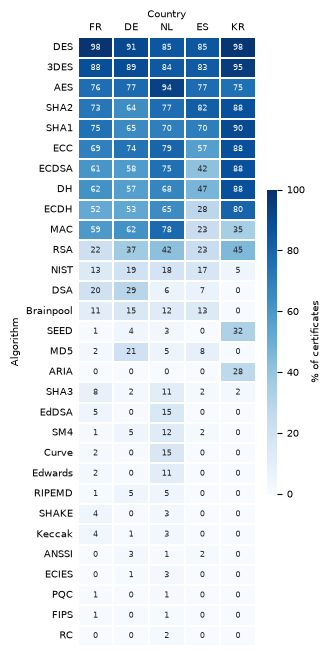

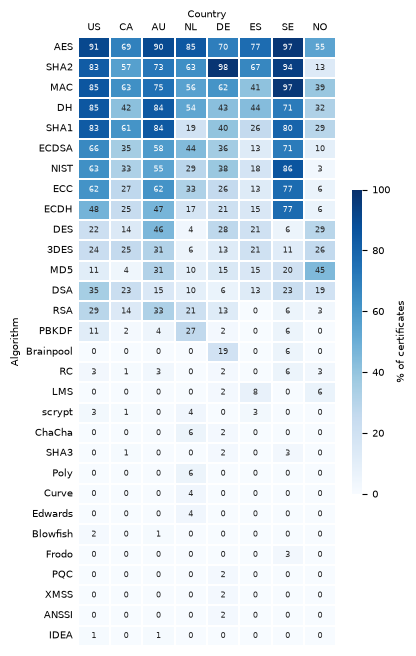

In [21]:
for category, slug in [("Smart Cards", "smartcards"), ("Network Devices and Systems", "network")]:
    in_category = cc_certs["Category"] == category
    share = country_algorithm_share(cc_certs[in_category], cc_mentions[cc_mentions["Category"] == category],
                                    min_certs=30)
    plot_share_heatmap(share, f"CC {category}: share of certificates mentioning each algorithm, by scheme",
                       f"./img/cc_country_algorithm_heatmap_{slug}.png")

#### Controlling for issue period (CC)
**Why:** schemes were active in different periods. UK certificates in the dataset run from 1998 to 2017 with a median of 2006, while NL, SE and IT are mostly from after 2018. Algorithm usage changed over time (DES/3DES, MD5 and SHA-1 were phased out, while SHA-2, ECC and PBKDF became common), so part of the country differences above comes from *when* a scheme certified, not *where*.

**What the cells do:**
1. The first cell prints, for each scheme with ≥ `MIN_CERTS` certificates, the first, median and last issue year and the % of its certificates issued in or after `PERIOD_SPLIT` (2017, the median issue year across the dataset).
2. The second cell splits the certificates at `PERIOD_SPLIT` and draws the country × algorithm heatmap for each period (`img/cc_country_algorithm_heatmap_older.png` and `..._recent.png`). Only schemes with ≥ 30 certificates in a period are shown. It then prints a side-by-side table for the algorithms whose use changed most over time. `NaN` means the scheme has fewer than 30 certificates in that period. If a country's value is similar in both periods, the difference is not explained by era.

In [13]:
PERIOD_SPLIT = 2017  # dataset-wide median issue year

years = cc_certs.groupby("Country")["Year"]
year_summary = pd.DataFrame({
    "Certificates": years.size(),
    "FirstYear": years.min(),
    "MedianYear": years.median(),
    "LastYear": years.max(),
    f"% from {PERIOD_SPLIT}+": years.apply(lambda y: (y >= PERIOD_SPLIT).mean() * 100).round(0),
})
print(f"Dataset-wide median issue year: {cc_certs['Year'].median():.0f}")
year_summary[year_summary["Certificates"] >= MIN_CERTS].sort_values("MedianYear")

Dataset-wide median issue year: 2017


,Certificates,FirstYear,MedianYear,LastYear,% from 2017+
Country,,,,,
UK,123,1998,2006.0,2017,3.0
DE,1127,1999,2014.0,2026,43.0
JP,728,2003,2014.0,2026,41.0
CA,575,1997,2016.0,2026,43.0
NO,111,2004,2016.0,2026,39.0
AU,140,2000,2016.0,2026,45.0
KR,181,2006,2017.0,2026,52.0
FR,1311,1999,2017.0,2026,52.0
TR,89,2010,2017.0,2026,57.0


CC certificates issued before 2017: share mentioning each algorithm, by scheme
CC certificates issued 2017 and later: share mentioning each algorithm, by scheme


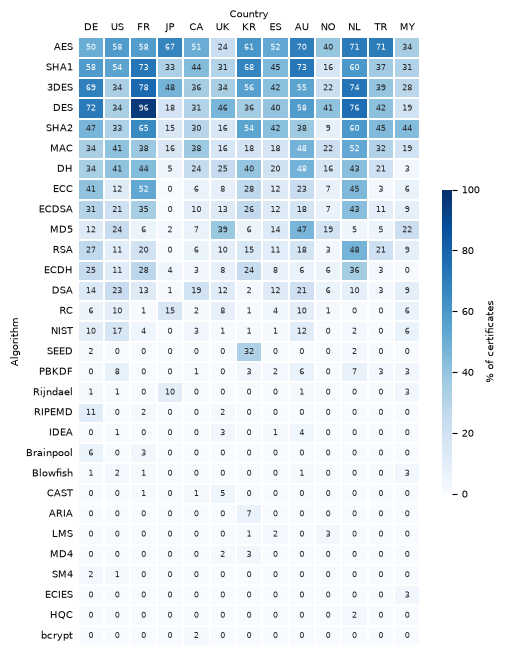

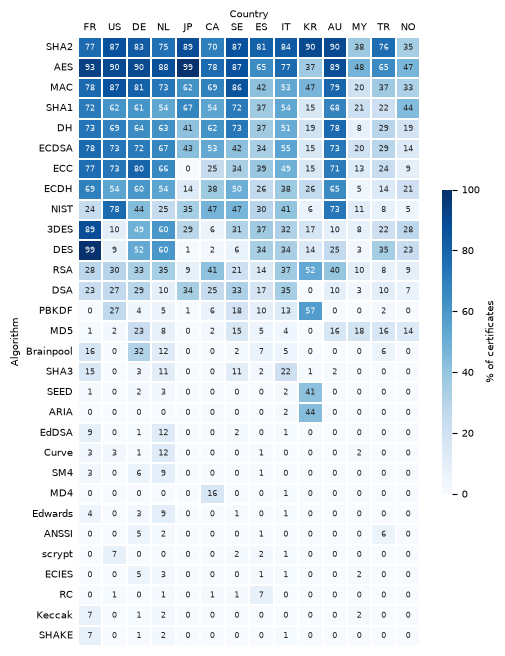

before 2017                                            \
Algorithm         DES  3DES   MD5  SHA1  SHA2   AES   ECC PBKDF   
Country                                                           
DE               72.0  69.0  12.0  58.0  47.0  50.0  41.0   0.0   
US               34.0  34.0  24.0  54.0  33.0  58.0  12.0   8.0   
FR               96.0  78.0   6.0  73.0  65.0  58.0  52.0   0.0   
JP               18.0  48.0   2.0  33.0  15.0  67.0   0.0   0.0   
CA               31.0  36.0   7.0  44.0  30.0  51.0   6.0   1.0   
UK               46.0  34.0  39.0  31.0  16.0  24.0   8.0   0.0   
KR               36.0  56.0   6.0  68.0  54.0  61.0  28.0   3.0   
ES               40.0  42.0  14.0  45.0  42.0  52.0  12.0   2.0   
AU               58.0  55.0  47.0  73.0  38.0  70.0  23.0   6.0   
NO               41.0  22.0  19.0  16.0   9.0  40.0   7.0   0.0   
NL               76.0  74.0   5.0  60.0  60.0  71.0  45.0   7.0   
TR               42.0  39.0   5.0  37.0  45.0  71.0   3.0   3.0   
MY               19.0  28.0  22.0  31.0  44.0  34.0   6.0   3.0   
SE                NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
IT                NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   

          2017 and later                                            
Algorithm            DES  3DES   MD5  SHA1  SHA2   AES   ECC PBKDF  
Country                                                             
DE                  52.0  49.0  23.0  61.0  83.0  90.0  80.0   4.0  
US                   9.0  10.0   2.0  62.0  87.0  90.0  73.0  27.0  
FR                  99.0  89.0   1.0  72.0  77.0  93.0  77.0   0.0  
JP                   1.0  29.0   0.0  67.0  89.0  99.0   0.0   1.0  
CA                   2.0   6.0   2.0  54.0  70.0  78.0  25.0   6.0  
UK                   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  
KR                  14.0  17.0   0.0  15.0  90.0  37.0  15.0  57.0  
ES                  34.0  37.0   5.0  37.0  81.0  65.0  39.0  10.0  
AU                  25.0  10.0  16.0  68.0  90.0  89.0  71.0   0.0  
NO                  23.0  28.0  14.0  44.0  35.0  47.0   9.0   0.0  
NL                  60.0  60.0   8.0  54.0  75.0  88.0  66.0   5.0  
TR                  35.0  22.0  16.0  22.0  76.0  65.0  24.0   2.0  
MY                   3.0   8.0  18.0  21.0  38.0  48.0  13.0   0.0  
SE                   6.0  31.0  15.0  72.0  87.0  87.0  34.0  18.0  
IT                  34.0  32.0   4.0  54.0  84.0  77.0  49.0  13.0

In [22]:
periods = {
    f"before {PERIOD_SPLIT}": ("older", lambda year: year < PERIOD_SPLIT),
    f"{PERIOD_SPLIT} and later": ("recent", lambda year: year >= PERIOD_SPLIT),
}
period_shares = {}
for label, (slug, in_period) in periods.items():
    share = country_algorithm_share(cc_certs[in_period(cc_certs["Year"])],
                                    cc_mentions[in_period(cc_mentions["Year"])], min_certs=30)
    period_shares[label] = share
    plot_share_heatmap(share, f"CC certificates issued {label}: share mentioning each algorithm, by scheme",
                       f"./img/cc_country_algorithm_heatmap_{slug}.png")

# Algorithms whose use changed most over time: does a scheme's apparent preference survive within a period?
TIME_SENSITIVE = ["DES", "3DES", "MD5", "SHA1", "SHA2", "AES", "ECC", "PBKDF"]
pd.concat({label: share.reindex(columns=TIME_SENSITIVE, fill_value=0).round(0)
           for label, share in period_shares.items()}, axis=1)

**Findings from the period split:**
- **UK** appears only before 2017 (3 % of its certificates are later). Its low AES/SHA-2 and high MD5 in the overall heatmap are an era effect. UK cannot be compared with schemes that are active today.
- **SE and IT** appear only from 2017 on, so their "modern" profile (e.g. IT SHA-3) is also partly an era effect.
- **FR DES** stays at 96–99 % in both periods, so it is a product-mix effect (smart cards, see above), not an era effect. In contrast, US DES drops from 34 % to 9 % and JP DES from 18 % to 1 %.
- **KR**: SEED (32 → 41 %) and ARIA (7 → 44 %) *increase* after 2017, and PBKDF is almost entirely recent (3 → 57 %). These are current national preferences, not legacy ones.
- **JP ECC** is 0 % in both periods while ECDSA/ECDH are not. This is probably wording (JP documents use specific curve or scheme names rather than "ECC") rather than a real absence. Check before interpreting it.

### OpenSSL
The rest of the notebook asks how OpenSSL relates to the country and algorithm patterns above.

**What the next cell does:** it marks every certificate as OpenSSL-based or not by adding a boolean `OpenSSL` column to `cc_certs`, `cc_mentions`, `fips_certs` and `fips_mentions`. All cells below use this column. A certificate counts as OpenSSL-based if `OpenSSL` appears among its `crypto_library` keywords: in the report or the ST for CC, and in the security policy for FIPS 140. This is the same signal `get_cc_library_mentions` / `get_fips_library_mentions` use. Certificates that use the OpenSSL API without naming it (see `openssl_api_detection.ipynb`) are not counted. The cell prints how many certificates mention OpenSSL.

In [15]:
def mentions_library(*keyword_dicts, name="OpenSSL"):
    return any(kw and name in (kw.get("crypto_library") or {}) for kw in keyword_dicts)


cc_openssl = {c.dgst for c in cc_dataset if mentions_library(c.pdf_data.report_keywords, c.pdf_data.st_keywords)}
fips_openssl = {c.dgst for c in fips_dataset if mentions_library(c.pdf_data.keywords)}

for certs, mentions, openssl in ((cc_certs, cc_mentions, cc_openssl), (fips_certs, fips_mentions, fips_openssl)):
    certs["OpenSSL"] = certs["Dgst"].isin(openssl)
    mentions["OpenSSL"] = mentions["Dgst"].isin(openssl)

print(f"CC: {cc_certs['OpenSSL'].sum()} of {len(cc_certs)} certificates mention OpenSSL")
print(f"FIPS: {fips_certs['OpenSSL'].sum()} of {len(fips_certs)} certificates mention OpenSSL")

CC: 1196 of 6819 certificates mention OpenSSL
FIPS: 968 of 5423 certificates mention OpenSSL


#### OpenSSL adoption by country
**Question:** in which countries do certificates mention OpenSSL most often?

**What the cell does:** it computes the % of each country's certificates that mention OpenSSL and draws three bar charts, one above another:
- **CC (all):** every certificate of countries with ≥ `MIN_CERTS` certificates.
- **CC (network devices):** only network devices, because OpenSSL is concentrated in that category and the scheme product mixes differ (countries with ≥ 30 network-device certificates).
- **FIPS 140:** by vendor country. Each country reflects only a handful of large vendors.

The number under each country code is the country's certificate count. The dashed line is the OpenSSL share across all countries shown in that panel. Like the heatmaps, the figure is drawn at its printed thesis size and saved as `img/openssl_share_by_country.png` and `.pdf`. The table under it repeats the shares.

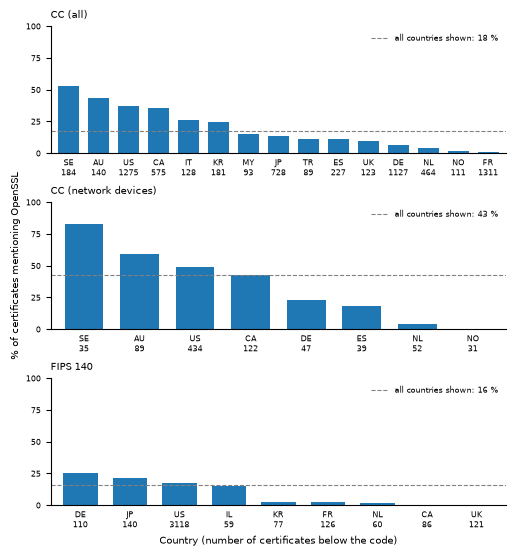

,CC (all),CC (network devices),FIPS 140
Country,,,
SE,52.7,82.9,NaN
AU,43.6,59.6,NaN
US,37.1,48.6,17.5
CA,35.7,42.6,0.0
IT,25.8,NaN,NaN
KR,24.3,NaN,2.6
MY,15.1,NaN,NaN
JP,13.5,NaN,21.4
TR,11.2,NaN,NaN


In [23]:
def openssl_share_by_country(certs, min_certs=MIN_CERTS):
    known = certs[certs["Country"] != "Unknown"]
    stats = known.groupby("Country")["OpenSSL"].agg(Certificates="size", OpenSSL="sum")
    stats = stats[stats["Certificates"] >= min_certs]
    stats["Share"] = stats["OpenSSL"] / stats["Certificates"] * 100
    return stats.sort_values("Share", ascending=False)


cc_network = cc_certs[cc_certs["Category"] == "Network Devices and Systems"]
openssl_by_country = {
    "CC (all)": openssl_share_by_country(cc_certs),
    "CC (network devices)": openssl_share_by_country(cc_network, min_certs=30),
    "FIPS 140": openssl_share_by_country(fips_certs),
}

# Drawn at printed thesis size (see plot_share_heatmap): one panel per row, with the
# sample size under each country code instead of above the bar.
with plt.rc_context({"font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7,
                     "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6}):
    fig, axes = plt.subplots(3, 1, figsize=(THESIS_TEXT_WIDTH, 5.4), sharey=True)
    for ax, (label, stats) in zip(axes, openssl_by_country.items()):
        overall = stats["OpenSSL"].sum() / stats["Certificates"].sum() * 100
        positions = range(len(stats))
        ax.bar(positions, stats["Share"], color="tab:blue", width=0.7)
        ax.axhline(overall, color="grey", linestyle="--", linewidth=0.8,
                   label=f"all countries shown: {overall:.0f} %")
        ax.set_xticks(list(positions), [f"{c}\n{n}" for c, n in zip(stats.index, stats["Certificates"])])
        ax.set_xlim(-0.6, max(len(stats), 8) - 0.4)  # same bar width in every panel
        ax.set_ylim(0, 100)
        ax.set_title(label, loc="left")
        ax.legend(loc="upper right", frameon=False)
        ax.tick_params(axis="x", length=0)
        ax.spines[["top", "right"]].set_visible(False)
    axes[1].set_ylabel("% of certificates mentioning OpenSSL")
    axes[-1].set_xlabel("Country (number of certificates below the code)")
    fig.tight_layout(pad=0.2, h_pad=0.8)
    fig.savefig("./img/openssl_share_by_country.png", dpi=300)
    fig.savefig("./img/openssl_share_by_country.pdf")
plt.show()

pd.concat({k: v["Share"].round(1) for k, v in openssl_by_country.items()}, axis=1)

#### Algorithms in OpenSSL-based vs. other certificates
**Question:** which algorithms are more (or less) common in OpenSSL-based certificates than in the rest?

**What the cell does:** for each algorithm it computes the % of OpenSSL certificates and the % of other certificates that mention it, keeps the 25 most-mentioned algorithms, and plots the difference in percentage points. Blue bars are algorithms that are more common with OpenSSL, and red bars are less common. For CC only network devices are compared, so the product mix doesn't distort the result. FIPS uses all certificates, including those with unknown country. The plot is drawn at its printed thesis size and saved as `img/openssl_algorithm_gap.png` and `.pdf`. The table under it holds the underlying shares.

**Caveat:** OpenSSL-based documents tend to list OpenSSL's whole algorithm catalogue, so OpenSSL certificates mention almost *every* algorithm more often. The useful signal is in the relative sizes and the red bars (e.g. 3DES in CC network devices), not in the fact that most bars are blue.

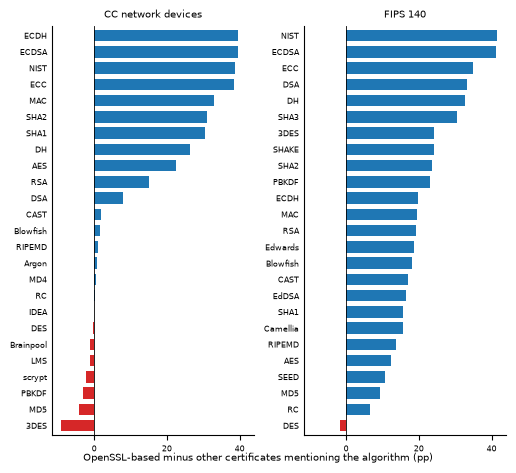

CC network devices                    FIPS 140                   
                       Other OpenSSL Difference    Other OpenSSL Difference
Algorithm                                                                  
AES                     72.0    94.6       22.6     87.4    99.8       12.4
SHA2                    58.8    89.8       31.0     67.0    90.7       23.7
MAC                     56.7    89.5       32.8     79.9    99.3       19.4
SHA1                    52.3    82.9       30.5     79.2    94.8       15.6
DH                      54.6    81.1       26.5     57.1    89.8       32.6
ECDSA                   32.7    72.1       39.4     42.7    83.8       41.1
NIST                    31.0    69.6       38.6     36.5    78.0       41.5
ECC                     29.2    67.8       38.6     29.7    64.5       34.8
ECDH                    19.8    59.3       39.5     25.8    45.7       19.9
RSA                     15.3    30.4       15.1     30.4    49.6       19.2
DSA                     20.7    28.6        7.9     40.5    73.8       33.2
3DES                    25.7    16.6       -9.1     59.7    83.8       24.1
DES                     22.4    22.0       -0.4     59.9    58.2       -1.7
MD5                     19.0    14.8       -4.1     46.6    55.8        9.2
PBKDF                    8.9     5.9       -3.0     13.0    36.1       23.1
Blowfish                 0.9     2.6        1.7      7.6    25.7       18.1
RC                       2.3     2.6        0.3     26.5    33.2        6.7
scrypt                   2.4     0.3       -2.2      NaN     NaN        NaN
CAST                     0.0     1.8        1.8     13.1    30.3       17.1
Brainpool                1.6     0.5       -1.1      NaN     NaN        NaN
LMS                      1.2     0.0       -1.2      NaN     NaN        NaN
RIPEMD                   0.0     1.0        1.0      8.6    22.4       13.8
IDEA                     0.7     0.8        0.1      NaN     NaN        NaN
Argon                    0.0     0.8        0.8      NaN     NaN        NaN
MD4                      0.3     0.8        0.4      NaN     NaN        NaN
SHA3                     NaN     NaN        NaN      8.3    38.8       30.6
SHAKE                    NaN     NaN        NaN      0.6    24.7       24.1
Edwards                  NaN     NaN        NaN      3.2    21.8       18.6
Camellia                 NaN     NaN        NaN      5.5    21.1       15.6
SEED                     NaN     NaN        NaN      7.9    18.6       10.7
EdDSA                    NaN     NaN        NaN      1.9    18.5       16.6

In [24]:
def openssl_algorithm_gap(certs, mentions, top=25):
    """Share of OpenSSL vs. other certificates mentioning each algorithm, in percentage points."""
    totals = certs["OpenSSL"].value_counts()
    counts = mentions.groupby(["Algorithm", "OpenSSL"])["Dgst"].nunique().unstack(fill_value=0)
    share = counts.div(totals, axis=1) * 100
    share = share.rename(columns={True: "OpenSSL", False: "Other"}).rename_axis(columns=None)
    share["Difference"] = share["OpenSSL"] - share["Other"]
    return share.loc[share[["OpenSSL", "Other"]].max(axis=1).sort_values(ascending=False).head(top).index]


cc_network_mentions = cc_mentions[cc_mentions["Category"] == "Network Devices and Systems"]
gaps = {
    "CC network devices": openssl_algorithm_gap(cc_network, cc_network_mentions),
    "FIPS 140": openssl_algorithm_gap(fips_certs, fips_mentions),
}

# Drawn at printed thesis size (see plot_share_heatmap).
with plt.rc_context({"font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7,
                     "xtick.labelsize": 6, "ytick.labelsize": 6}):
    fig, axes = plt.subplots(1, 2, figsize=(THESIS_TEXT_WIDTH, 4.6), sharex=True)
    for ax, (label, gap) in zip(axes, gaps.items()):
        gap = gap.sort_values("Difference")
        colors = ["tab:red" if d < 0 else "tab:blue" for d in gap["Difference"]]
        ax.barh(gap.index, gap["Difference"], color=colors, height=0.7)
        ax.axvline(0, color="black", linewidth=0.6)
        ax.set_title(label)
        ax.tick_params(axis="y", length=0)
        ax.spines[["top", "right"]].set_visible(False)
        ax.margins(y=0.01)
    fig.supxlabel("OpenSSL-based minus other certificates mentioning the algorithm (pp)", fontsize=7)
    fig.tight_layout(pad=0.2, w_pad=1.0)
    fig.savefig("./img/openssl_algorithm_gap.png", dpi=300)
    fig.savefig("./img/openssl_algorithm_gap.pdf")
plt.show()

pd.concat({k: v.round(1) for k, v in gaps.items()}, axis=1)

#### National ciphers and OpenSSL
**Question:** when a certificate mentions a national cipher, is that because it uses OpenSSL? OpenSSL ships SEED and ARIA (Korea), Camellia (Japan) and SM4 (China). GOST (Russia) is available only through an external engine.

**What the cell does:** for each cipher and each dataset, it splits the certificates into two scopes, the cipher's home country and all other known countries. For each scope it reports:
- `CertsMentioning`: how many certificates mention the cipher.
- `OpenSSLShareOfThose`: what % of those certificates are OpenSSL-based.
- `OpenSSLShareBaseline`: what % of *all* certificates in the scope are OpenSSL-based, for comparison.

If `OpenSSLShareOfThose` is well above the baseline, OpenSSL is probably why the cipher appears. Combinations where no certificate mentions the cipher are left out (e.g. CC has no CN or RU scheme). The table is saved to `results/openssl_national_ciphers.csv`.

**Results:**
- In FIPS, outside the home country, SEED, ARIA, Camellia and SM4 mentions are OpenSSL-based about twice as often as the baseline (26–38 % vs. ~16 %).
- In CC, Korean certificates that mention SEED or ARIA are *less* often OpenSSL-based than Korean certificates overall (19 % / 13 % vs. 24 %). This suggests Korean vendors use their own (KCMVP) implementations.
- Very small groups (CC ARIA elsewhere with n=4, GOST) are not interpretable.

In [18]:
NATIONAL_CIPHERS = {"SEED": "KR", "ARIA": "KR", "Camellia": "JP", "SM4": "CN", "GOST": "RU"}

rows = []
for dataset_name, certs, mentions in (("CC", cc_certs, cc_mentions), ("FIPS 140", fips_certs, fips_mentions)):
    for cipher, home in NATIONAL_CIPHERS.items():
        for scope, in_scope in (("home country", certs["Country"] == home),
                                ("elsewhere", (certs["Country"] != home) & (certs["Country"] != "Unknown"))):
            scoped = certs[in_scope]
            mentioning = set(mentions.loc[mentions["Algorithm"] == cipher, "Dgst"]) & set(scoped["Dgst"])
            if not mentioning:
                continue
            openssl_mentioning = scoped[scoped["Dgst"].isin(mentioning)]["OpenSSL"].sum()
            rows.append({"Dataset": dataset_name, "Cipher": cipher, "Home": home, "Scope": scope,
                         "CertsMentioning": len(mentioning),
                         "OpenSSLShareOfThose": round(openssl_mentioning / len(mentioning) * 100, 1),
                         "OpenSSLShareBaseline": round(scoped["OpenSSL"].mean() * 100, 1)})

national_openssl = pd.DataFrame(rows)
national_openssl.to_csv("./results/openssl_national_ciphers.csv", index=False)
national_openssl

,Dataset,Cipher,Home,Scope,CertsMentioning,OpenSSLShareOfThose,OpenSSLShareBaseline
0,CC,SEED,KR,home country,67,19.4,24.3
1,CC,SEED,KR,elsewhere,49,4.1,17.4
2,CC,ARIA,KR,home country,47,12.8,24.3
3,CC,ARIA,KR,elsewhere,4,100.0,17.4
4,CC,Camellia,JP,elsewhere,4,0.0,18.0
5,CC,SM4,CN,elsewhere,111,18.9,17.5
6,CC,GOST,RU,elsewhere,1,0.0,17.5
7,FIPS 140,SEED,KR,home country,1,0.0,2.6
8,FIPS 140,SEED,KR,elsewhere,428,26.4,16.5
9,FIPS 140,ARIA,KR,elsewhere,87,26.4,16.5
